In [1]:
import xesmf as xe
import xarray as xr
import cartopy.crs as ccrs
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cm
from netCDF4 import Dataset
import urllib.request

In [2]:
from dask_jobqueue import SLURMCluster  # setup dask cluster 
from dask.distributed import Client

cluster = SLURMCluster(
    cores=4,
    memory='15GB',
    walltime='01:00:00',
    queue='compute',
    #interface='ib0', 
    #job_extra_directives=["--reservation poworkshop"]
)
cluster.scale(jobs=1)
client = Client(cluster)
client

Connection method: Cluster object,Cluster type: dask_jobqueue.SLURMCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://10.151.1.104:44305,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


## Read in ERA5 Data

In [11]:
era5_data_path = "/proj/cmip6/data/era5/reanalysis/single-levels/monthly-means/"

def preprocess(ds): 
    tmp = ds#.resample(valid_time="YE").mean() # where YE is for years
    return tmp 
    
#10m u-wind
u10m = xr.open_mfdataset(era5_data_path + "10m_u_component_of_wind/2023*.nc", 
                         engine = "netcdf4", preprocess = preprocess)

#10m v-wind
v10m = xr.open_mfdataset(era5_data_path + "10m_v_component_of_wind/2023*.nc", 
                         engine = "netcdf4", preprocess = preprocess)

wind_ds = xr.merge([u10m, v10m], compat = "minimal") #minimal means I only want to merge the data that has the same coordinates

wind_ds["speed"] = np.sqrt(wind_ds["u10"]**2 + wind_ds["v10"]**2)

sfc_pressure = xr.open_mfdataset(era5_data_path + "surface_pressure/2023*.nc", 
                         engine = "netcdf4", preprocess = preprocess)

In [19]:
wind_ds

<xarray.Dataset> Size: 150MB
Dimensions:     (valid_time: 12, latitude: 721, longitude: 1440)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 96B 2023-01-01 ... 2023-12-01
    expver      (valid_time) <U4 192B '0001' '0001' '0001' ... '0001' '0001'
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude   (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    number      int64 8B 0
Data variables:
    u10         (valid_time, latitude, longitude) float32 50MB dask.array<chunksize=(6, 361, 720), meta=np.ndarray>
    v10         (valid_time, latitude, longitude) float32 50MB dask.array<chunksize=(6, 361, 720), meta=np.ndarray>
    speed       (valid_time, latitude, longitude) float32 50MB dask.array<chunksize=(6, 361, 720), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-02-02T15:53 GRIB to CDM+CF via cfgrib-0.9.1...

## Correlate pressure and wind data 

In [13]:
pressure_wind_correlations = xr.corr(sfc_pressure["sp"], wind_ds["speed"], dim = "valid_time")
pressure_wind_correlations = pressure_wind_correlations.compute()

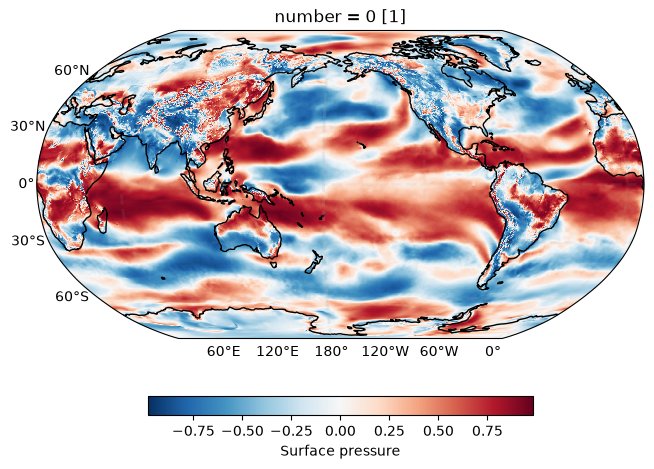

In [14]:
fig, ax = plt.subplots(figsize=[20,5], subplot_kw={'projection':ccrs.Robinson(190)})
pressure_wind_correlations.plot(ax=ax, transform = ccrs.PlateCarree(), 
                               cbar_kwargs = dict(orientation = "horizontal", fraction = 0.05))
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=2, alpha=0.1, linestyle='--')
gl.top_labels = False
gl.right_labels = False

ax.coastlines()

## Select a location to analyze

In [15]:
ds_locs = xr.Dataset()

ds_locs["lon"] = xr.DataArray(
    data=[-120], dims=("locations")
)
ds_locs["lat"] = xr.DataArray(data=[-20], dims=("locations"))

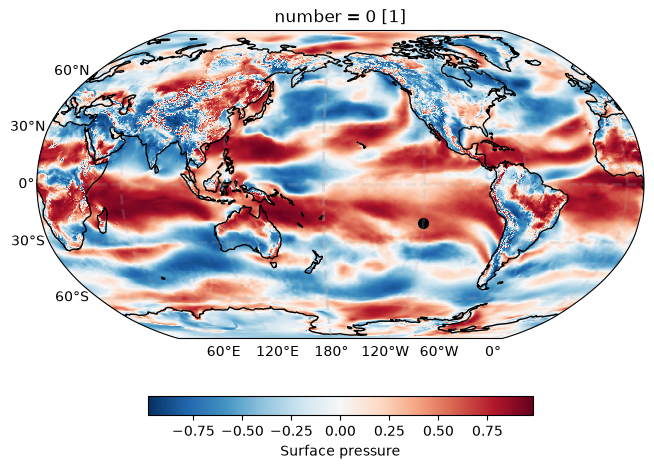

In [16]:
fig, ax = plt.subplots(figsize=[20,5], subplot_kw={'projection':ccrs.Robinson(190)})
pressure_wind_correlations.plot(ax=ax, transform = ccrs.PlateCarree(), 
                               cbar_kwargs = dict(orientation = "horizontal", fraction = 0.05))
ax.scatter(ds_locs["lon"], ds_locs["lat"], transform = ccrs.PlateCarree(), s = 50, c = "k")
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=2, alpha=0.2, linestyle='--')
gl.top_labels = False
gl.right_labels = False
ax.coastlines()

## Interpolate fields to spot

In [17]:
regridder = xe.Regridder(wind_ds, ds_locs, "bilinear", locstream_out=True)
subsampled_wind_ds = regridder(wind_ds).compute()
subsampled_pressure_ds = regridder(sfc_pressure).compute()

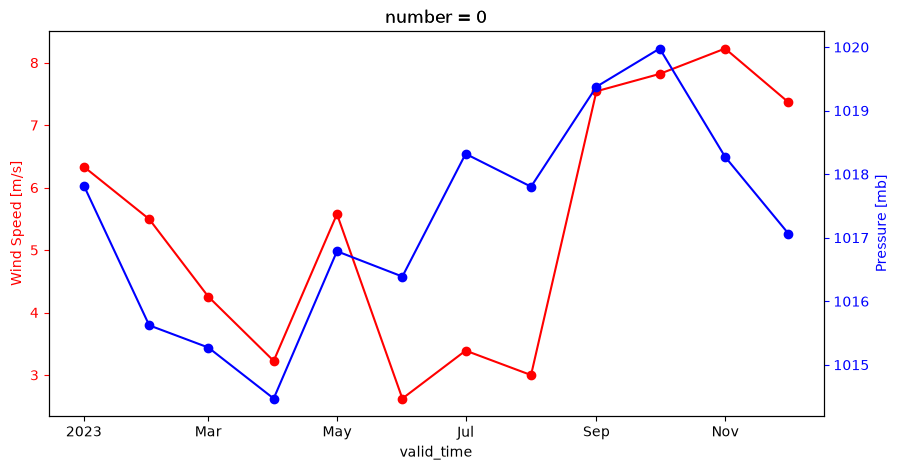

In [18]:
fig, ax = plt.subplots(figsize = (10, 5))

wind_speed = subsampled_wind_ds.speed
surface_pressure = subsampled_pressure_ds.sp / 100 #Pa -> millibars

wind_speed.plot(ax = ax, c = "red", marker = "o")
ax.set_ylabel("Wind Speed [m/s]", c = "red")
ax.tick_params(axis='y', colors='red')

ax2 = ax.twinx()
surface_pressure.plot(ax = ax2, marker = "o", c = "b")
ax2.set_ylabel("Pressure [mb]", c = "b")
ax2.tick_params(axis='y', colors='b')